<a href="https://colab.research.google.com/github/Iucasoa/Sistemas-Inteligentes/blob/main/problema2-regressao-logistica/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problema 2: Regressão Logística para Previsão de Doenças Cardíacas

Neste trabalho vamos construir um modelo de regressão logística para prever a presença de doença cardíaca a partir de dados clínicos, utilizando o *dataset* **Heart Disease (Cleveland)**. O fluxo segue o notebook de regressão logística da disciplina (`06_Regressao_Logistica.ipynb`).

Vamos importar as bibliotecas necessárias:

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, roc_auc_score, roc_curve, accuracy_score,
    precision_score, recall_score, f1_score, classification_report
)

Realizando algumas configurações nos plots:

In [2]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams['mathtext.rm'] = "Arial"
plt.rcParams['mathtext.it'] = "Arial:italic"
plt.rcParams['mathtext.bf'] = "Arial:bold"
plt.rcParams['figure.figsize'] = (8, 5)

# Pasta onde as figuras usadas no relatório são salvas
os.makedirs("figuras", exist_ok=True)

## 1. Conjunto de Dados

O *dataset* possui 303 pacientes e 13 variáveis clínicas, e é carregado diretamente do repositório da UCI pelo pacote `ucimlrepo` (no Google Colab é necessário instalá-lo):

In [ ]:
%pip install -q --disable-pip-version-check ucimlrepo

In [4]:
from ucimlrepo import fetch_ucirepo

heart = fetch_ucirepo(id=45)

df = heart.data.features.copy()
df["target"] = heart.data.targets.iloc[:, 0]
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


* `age`: idade (anos); `sex`: sexo biológico (1 = masculino, 0 = feminino);
* `cp`: tipo de dor no peito (1 típica, 2 atípica, 3 não anginosa, 4 assintomática);
* `trestbps`: pressão arterial em repouso (mmHg); `chol`: colesterol sérico (mg/dl);
* `fbs`: glicemia em jejum > 120 mg/dl; `restecg`: ECG em repouso (0, 1 ou 2);
* `thalach`: frequência cardíaca máxima; `exang`: angina induzida por exercício;
* `oldpeak`: depressão do segmento ST; `slope`: inclinação do segmento ST (1, 2 ou 3);
* `ca`: nº de artérias com obstrução visível (0 a 3); `thal`: cintilografia de tálio (3, 6 ou 7);
* `target`: diagnóstico original (0 a 4).

In [5]:
print(f"Quantidade de amostras = {df.shape[0]}")
print(f"Quantidade de features = {df.shape[1] - 1}")

Quantidade de amostras = 303
Quantidade de features = 13


## 2. Pré-processamento

### 2.1 Dados incompletos

Diagnosticando onde estão os valores faltantes:

In [6]:
print("Faltantes por coluna:")
print(df.isna().sum())

Faltantes por coluna:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


In [7]:
print("Linhas com algum faltante:")
display(df[df.isna().any(axis=1)])

Linhas com algum faltante:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
87,53,0,3,128,216,0,2,115,0,0.0,1,0.0,NaN,0
166,52,1,3,138,223,0,0,169,0,0.0,1,NaN,3.0,0
192,43,1,4,132,247,1,2,143,1,0.1,2,NaN,7.0,1
266,52,1,4,128,204,1,0,156,1,1.0,2,0.0,NaN,2
287,58,1,2,125,220,0,0,144,0,0.4,2,NaN,7.0,0
302,38,1,3,138,175,0,0,173,0,0.0,1,NaN,3.0,0


Há apenas 6 linhas incompletas (`ca` e `thal`), cerca de 2% do *dataset*. Como a perda é pequena, o tratamento escolhido foi **remover** essas linhas (a alternativa seria imputar a moda, já que `ca` e `thal` são discretas):

In [8]:
antes = len(df)
df = df.dropna().reset_index(drop=True)
print(f"Linhas antes: {antes} | depois: {len(df)} | removidas: {antes - len(df)}")

Linhas antes: 303 | depois: 297 | removidas: 6


### 2.2 Dados redundantes

In [9]:
print("Linhas duplicadas:", df.duplicated().sum())

Linhas duplicadas: 0


### 2.3 Binarização da variável alvo

O diagnóstico original vai de 0 (ausência de doença) a 4 (graus crescentes de doença). Como queremos prever apenas a **presença** ou **ausência** de doença, o alvo é binarizado: 0 = sem doença e 1 = com doença (qualquer valor maior que 0):

In [10]:
print("Alvo original (0 a 4):")
print(df["target"].value_counts().sort_index())

df["target"] = (df["target"] > 0).astype(int)

y = df["target"].to_numpy()
print(f"\nQuantidade de pacientes sem doença (0) = {np.bincount(y)[0]}")
print(f"Quantidade de pacientes com doença (1) = {np.bincount(y)[1]}")

Alvo original (0 a 4):
target
0    160
1     54
2     35
3     35
4     13
Name: count, dtype: int64

Quantidade de pacientes sem doença (0) = 160
Quantidade de pacientes com doença (1) = 137


### 2.4 Divisão em treino e teste

Vamos dividir nosso *dataset* em 80% para treinamento e 20% para teste. A divisão é **estratificada** (`stratify=y`), mantendo a proporção de doentes e saudáveis nos dois conjuntos:

In [11]:
X = df.drop(columns="target")
feature_names = X.columns

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Treino: {X_train.shape[0]} amostras")
print(f"Teste:  {X_test.shape[0]} amostras")
print(f"Proporção de doentes no treino: {y_train.mean():.3f} | no teste: {y_test.mean():.3f}")

Treino: 237 amostras
Teste:  60 amostras
Proporção de doentes no treino: 0.460 | no teste: 0.467


### 2.5 Padronização

Como as variáveis possuem escalas muito diferentes (por exemplo, `chol` entre 126 e 564 e `oldpeak` entre 0 e 6,2), vamos utilizar a padronização. A média e o desvio padrão são calculados apenas no treinamento:

In [12]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)      # Nao é necessario o fit_transform pois a media e a variancia
                                           # ja foram calculados

## 3. Tarefa 1: Treinamento do Modelo

Agora vamos criar nosso modelo de regressão logística, com os parâmetros pedidos no enunciado, e realizar o treinamento:

In [13]:
model = LogisticRegression(
    solver='liblinear',
    random_state=42,
    max_iter=1000,     # máximo de iterações
)

model.fit(X_train_sc, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

O número de iterações necessárias para a convergência é dado pelo atributo `n_iter_`:

In [14]:
print(f"Iterações até a convergência: {model.n_iter_[0]}")

Iterações até a convergência: 5


Finalizado o treinamento, podemos obter os parâmetros do modelo através dos atributos `intercept_` e `coef_`:

In [15]:
t0 = model.intercept_
tvalues = model.coef_[0]

print(f"θ0 = {t0}")
print("\nθ1, θ2, ..., θ13 (ordenados por módulo):")
print(pd.Series(tvalues, index=feature_names).sort_values(key=abs, ascending=False).round(4))

θ0 = [-0.08614213]

θ1, θ2, ..., θ13 (ordenados por módulo):
ca          0.9589
thal        0.7387
cp          0.5083
sex         0.4840
oldpeak     0.4451
trestbps    0.4202
exang       0.3727
slope       0.3527
fbs        -0.3312
restecg     0.3040
chol        0.2223
thalach    -0.2071
age        -0.0371
dtype: float64


Com o vetor de parâmetros $\Phi$, a probabilidade de doença de um paciente é

$$
\hat{p} = \frac{1}{1 + e^{-\mathbf{x}^T\Phi}}
$$

e o paciente é classificado como "com doença" se $\hat{p} \geq 0{,}5$. Vamos verificar isso manualmente para o primeiro paciente do conjunto de teste:

In [16]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

theta = np.concatenate((t0, tvalues))

def model_predict(theta, x):
    z = np.dot(x, theta)
    p = sigmoid(z)
    status = 'com doença' if p >= 0.5 else 'sem doença'
    return status, p

X_example = np.concatenate(([1], X_test_sc[0]))

status, p = model_predict(theta, X_example)
print(f"Previsão = {status}\nProbabilidade (doença) = {p*100:.2f}%")
print(f"Probabilidade pela sklearn = {model.predict_proba(X_test_sc[[0]])[0, 1]*100:.2f}% | Real = {y_test[0]}")

Previsão = sem doença
Probabilidade (doença) = 2.07%
Probabilidade pela sklearn = 2.07% | Real = 0


## 4. Tarefa 2: Avaliação do Modelo

Utilizando o método `predict` para determinar a saída do modelo em todo o conjunto de teste, e `predict_proba` para as probabilidades associadas:

In [17]:
y_pred = model.predict(X_test_sc)
y_prob = model.predict_proba(X_test_sc)[:, 1]

A matriz de confusão é dada por:

In [18]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

VN, FP, FN, VP = cm.ravel()
print(f"\nVerdadeiros negativos (sem doença corretamente) = {VN}")
print(f"Falsos positivos (saudável classificado como doente) = {FP}")
print(f"Falsos negativos (doente classificado como saudável) = {FN}")
print(f"Verdadeiros positivos (com doença corretamente) = {VP}")

[[28  4]
 [ 6 22]]

Verdadeiros negativos (sem doença corretamente) = 28
Falsos positivos (saudável classificado como doente) = 4
Falsos negativos (doente classificado como saudável) = 6
Verdadeiros positivos (com doença corretamente) = 22


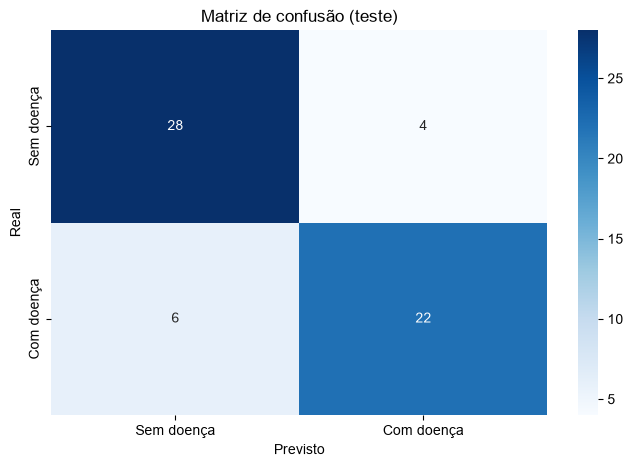

In [19]:
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Sem doença", "Com doença"],
            yticklabels=["Sem doença", "Com doença"])
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de confusão (teste)")
plt.savefig("figuras/matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

Podemos agora calcular as métricas de desempenho do nosso classificador:

In [20]:
print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precisão: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred):.4f}")

Acurácia: 0.8333
Precisão: 0.8462
Recall: 0.7857
F1-Score: 0.8148


In [21]:
print(classification_report(y_test, y_pred, target_names=["Sem doença", "Com doença"]))

              precision    recall  f1-score   support

  Sem doença       0.82      0.88      0.85        32
  Com doença       0.85      0.79      0.81        28

    accuracy                           0.83        60
   macro avg       0.83      0.83      0.83        60
weighted avg       0.83      0.83      0.83        60



A curva ROC e o valor do AUC podem ser obtidos através das funções `roc_curve` e `roc_auc_score`:

AUC-ROC:  0.9498


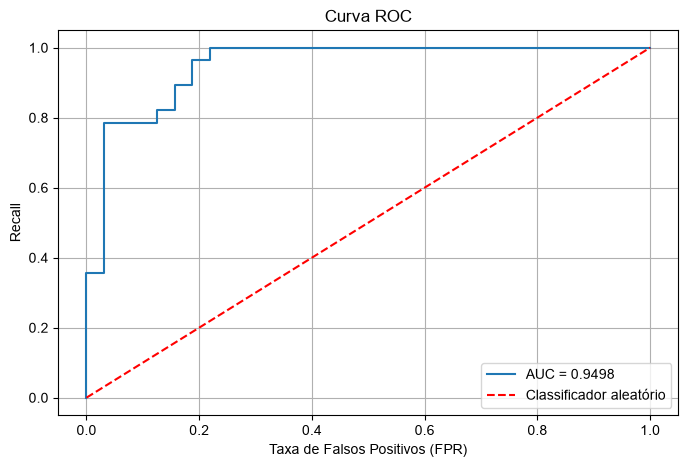

In [22]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

print(f"AUC-ROC:  {auc:.4f}")

plt.plot(fpr, tpr, label=f'AUC = {auc:.4f}')
plt.plot([0, 1], [0, 1], 'r--', label='Classificador aleatório')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Recall')
plt.title('Curva ROC')
plt.legend()
plt.grid()
plt.savefig("figuras/curva_roc.png", dpi=150, bbox_inches="tight")
plt.show()

Cada ponto da curva corresponde a um limiar de decisão. O primeiro ponto da curva que atinge recall igual a 1 (nenhum falso negativo), com o seu limiar e a taxa de falsos positivos correspondente, é:

In [23]:
i = np.argmax(tpr >= 1.0)
print(f"Limiar = {thresholds[i]:.4f} | Recall = {tpr[i]:.2f} | FPR = {fpr[i]:.4f}")

Limiar = 0.1868 | Recall = 1.00 | FPR = 0.2188
